# Relaxation

This guide covers spin relaxation: Redfield theory for rotational
diffusion (chemical shift anisotropy, dipolar and quadrupolar mechanisms,
with cross-correlations), the phenomenological T1/T2 and damping models,
the retention policies, and thermal equilibrium with the two
thermalisation methods. Read the [Liouville-space](liouville-space.ipynb) and
[solid-state](solid-state.ipynb) guides first: relaxation lives in Liouville
space and is driven by the same anisotropic interaction tensors. The
companion notebook is
[`notebooks/relaxation.ipynb`](relaxation.ipynb) ([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/relaxation.ipynb)).

Every Python block is executed by `tests/docs/`, in order and in one
namespace.

*Generated from [`docs/relaxation.md`](../relaxation.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Specifying relaxation](#Specifying-relaxation)
2. [Redfield theory](#Redfield-theory)
3. [Retention policies and dynamic frequency shifts](#Retention-policies-and-dynamic-frequency-shifts)
4. [T1/T2 and damping models](#T1/T2-and-damping-models)
5. [Thermal equilibrium and thermalisation](#Thermal-equilibrium-and-thermalisation)
6. [Transient NOE](#Transient-NOE)
7. [Relaxation in the contexts](#Relaxation-in-the-contexts)
8. [What is not ported yet](#What-is-not-ported-yet)
9. [Checking results against Spinach](#Checking-results-against-Spinach)

## Specifying relaxation

Relaxation is switched on by `inter["relaxation"]`, a list of theories,
and always needs two policies alongside it: `inter["rlx_keep"]`, which
terms of the superoperator to keep, and `inter["equilibrium"]`, where the
system relaxes to. The fields and their meanings are Spinach's:

| key | meaning |
|---|---|
| `relaxation` | `["redfield"]`, `["t1_t2"]`, `["damp"]`, `["SRFK"]`, `["SRSK"]`, or combinations |
| `rlx_keep` | `"labframe"` (everything), `"secular"`, `"kite"`, `"diagonal"` |
| `equilibrium` | `"zero"` (relax to nothing), `"IME"`, `"dibari"` |
| `tau_c` | one list of 1, 2 or 3 rotational correlation times (s) per chemical subsystem, for Redfield theory |
| `temperature` | Kelvin, default 298 |
| `rlx_dfs` | `"ignore"` (default) or `"keep"` the dynamic frequency shifts |
| `r1_rates`, `r2_rates` | per spin, Hz, scalar or 3x3 tensor, for `t1_t2` |
| `damp_rate` | Hz, scalar or 3x3 tensor, for `damp` |
| `srfk_tau_c` | list of `[weight, tau]` components (s) of the coupling modulation correlation function, for `SRFK` |
| `srfk_mdepth` | nspins x nspins nested list of root mean square modulation depths (Hz), `None` where a coupling is not modulated, for `SRFK` |
| `srsk_sources` | list of 0-based indices of the fast-relaxing source spins, for `SRSK` |

The settings are kept in `spin_system.rlx`. `relaxation(spin_system)` then returns the
superoperator `R` in Hz; it enters the Liouvillian as `L = H + 1j * R +
1j * K`, the convention of every Spinach pulse sequence.

In [1]:
import numpy as np
import scipy.linalg as sla
import spynach


def dense(x):
    return x.toarray() if hasattr(x, "toarray") else np.asarray(x)


spin_system_hc = spynach.create({"isotopes": ["1H", "13C"], "magnet": 14.1},
                   {"zeeman": {"scalar": [0.0, 0.0]}, "coordinates": [[0, 0, 0], [0, 0, 1.03]],
                    "relaxation": ["redfield"], "equilibrium": "dibari", "rlx_keep": "kite",
                    "temperature": 298, "tau_c": [[100e-12]]})
spin_system_hc = spynach.basis(spin_system_hc, {"formalism": "sphten-liouv", "approximation": "none"})
R = spynach.relaxation(spin_system_hc)

## Redfield theory

Bloch-Redfield-Wangsness theory treats the anisotropic part of the
Hamiltonian, modulated by rotational diffusion, as a perturbation of the
lab-frame isotropic Hamiltonian. Spynach uses Spinach's
diagonalisation-free form (Kuprov 2011): every pair of irreducible
components `Q[r][k][m]`, `Q[r][p][q]` of the anisotropic Hamiltonian (the
same `Q` as in the solid-state guide, here as commutation superoperators
in the lab frame) contributes

    R -= w * Q[r][k][m] * int_0^T exp(i L0 t) Q[r][p][q]^H exp(-i (L0 - i/tau) t) dt

where `L0` is the lab-frame Liouvillian, the weights `w` and decay rates
`1/tau` come from the rotational diffusion model (isotropic, axial or
rhombic, from one, two or three correlation times), and the integral is a
block of one matrix exponential (the auxiliary-matrix formalism of
Goodwin and Kuprov 2015, `spynach.relaxation.expmint`). No eigenvectors are
ever needed, so the method scales to restricted bases.

For a dipolar-coupled pair the result is the Solomon theory: with
`J(w) = tau_c / (1 + w^2 tau_c^2)` and the dipolar constant `b`, the auto-
and cross-relaxation rates are `rho_I = b^2/10 [J(wI-wS) + 3J(wI) +
6J(wI+wS)]` and `sigma = b^2/10 [6J(wI+wS) - J(wI-wS)]`. Reading them off
`R` between normalised `Lz` states:

In [2]:
Lz_H, Lz_C = spynach.state(spin_system_hc, ["Lz"], [0]), spynach.state(spin_system_hc, ["Lz"], [1])
rate = lambda bra, ket: -np.vdot(bra, dense(R) @ ket).real / np.sqrt(np.vdot(bra, bra).real * np.vdot(ket, ket).real)
b = (
    spin_system_hc.gammas[0]
    * spin_system_hc.gammas[1]
    * spin_system_hc.tols.hbar
    * spin_system_hc.tols.mu0
    / (4 * np.pi * 1.03e-10**3)
)
J = lambda w: 100e-12 / (1 + (w * 100e-12) ** 2)
wH, wC = abs(spin_system_hc.basefrqs[0]), abs(spin_system_hc.basefrqs[1])
print(f"Redfield: R1(1H) = {rate(Lz_H, Lz_H):.3f} Hz, sigma(HC) = {rate(Lz_H, Lz_C):.3f} Hz")
print(f"Solomon:  R1(1H) = {b**2 / 10 * (J(wH - wC) + 3 * J(wH) + 6 * J(wH + wC)):.3f} Hz, "
      f"sigma(HC) = {b**2 / 10 * (6 * J(wH + wC) - J(wH - wC)):.3f} Hz")

Redfield: R1(1H) = 2.553 Hz, sigma(HC) = 1.201 Hz
Solomon:  R1(1H) = 2.553 Hz, sigma(HC) = 1.201 Hz


The agreement is limited by the integral's truncation
(`tols.rlx_integration`, default 1e-4), as in Spinach. Redfield theory
requires `T1, T2 >> tau_c`; `relaxation` raises an error when a rate
violates it. Two correlation times give axial rotational diffusion
(`tau_c = [[tau_parallel, tau_perpendicular]]`), three give rhombic
diffusion (rank 2 only).

## Retention policies and dynamic frequency shifts

The full superoperator (`rlx_keep = "labframe"`) is only correct for lab
frame simulations. In the rotating frame, `"secular"` keeps the elements
between states of the same Zeeman frequency, `"kite"` keeps the
longitudinal block and the diagonal (what a NOESY needs), and
`"diagonal"` keeps only the self-relaxation rates. `rlx_dfs = "ignore"`
(the default) discards the imaginary part of `R`, the dynamic frequency
shifts:

In [3]:
def pair(keep, **extra):
    spin_system = spynach.create({"isotopes": ["1H", "13C"], "magnet": 14.1},
                       {"zeeman": {"scalar": [0.0, 0.0]}, "coordinates": [[0, 0, 0], [0, 0, 1.03]],
                        "relaxation": ["redfield"], "equilibrium": "zero", "rlx_keep": keep,
                        "temperature": 298, "tau_c": [[100e-12]], **extra})
    return spynach.basis(spin_system, {"formalism": "sphten-liouv", "approximation": "none"})

R_lab = dense(spynach.relaxation(pair("labframe", rlx_dfs="keep")))
R_diag = dense(spynach.relaxation(pair("diagonal")))
print(f"largest dynamic frequency shift {np.abs(R_lab.imag).max():.3g} rad/s; "
f"off-diagonal part of R_diag {np.abs(R_diag - np.diag(np.diag(R_diag))).max():.3g}")

largest dynamic frequency shift 0.891 rad/s; off-diagonal part of R_diag 0


## T1/T2 and damping models

`"t1_t2"` is the extended T1/T2 model: a diagonal superoperator in which
every basis state relaxes with the sum of the `r1_rates` of the spins it
carries longitudinally and the `r2_rates` of the spins it carries
transversely (3x3 tensors give orientation-dependent rates, projected on
the field direction at the orientation handed to `relaxation`).
`"damp"` damps every state except the unit state at `damp_rate`
(in Hilbert space, every element at half the rate):

In [4]:
spin_system_t1t2 = spynach.create({"isotopes": ["1H", "13C"], "magnet": 14.1},
                     {"relaxation": ["t1_t2", "damp"], "equilibrium": "zero", "rlx_keep": "diagonal",
                      "r1_rates": [1.0, 2.0], "r2_rates": [5.0, 7.0], "damp_rate": 0.5})
spin_system_t1t2 = spynach.basis(spin_system_t1t2, {"formalism": "sphten-liouv", "approximation": "none"})
R_t = dense(spynach.relaxation(spin_system_t1t2))
row = lambda spec: np.flatnonzero((spin_system_t1t2.basis.basis == spec).all(axis=1))[0]
print(R_t[row([2, 0]), row([2, 0])])          # Lz(H): R1 + damping
print(R_t[row([1, 3]), row([1, 3])])          # L+(H) L-(C): R2(H) + R2(C) + damping
print(R_t[0, 0])                              # the unit state never relaxes

(-1.5+0j)
(-12.5+0j)
0j


## Scalar relaxation of the first and second kind

Two mechanisms act through scalar couplings rather than through the
anisotropic interactions that Redfield theory integrates. Both are
Liouville-space theories and combine with the others in
`inter["relaxation"]`; Spinach evaluates them after Redfield theory and
so does spynach.

**First kind** (`"SRFK"`): a scalar coupling that jumps with a chemical
process (the nitrogen inversion of aziridines modulates the H-N
couplings on a millisecond scale) is a stochastic perturbation `H1(t)`
with correlation function `sum_i w_i exp(-t/tau_i)`. The superoperator is
the same Redfield integral as above with the lab-frame Hamiltonian as
`H0` and the modulation-depth Hamiltonian as `H1` (Spinach's
`rlx_scalar`): `R -= w * H1 int_0^T exp(i H0 t) H1 exp(-i (H0 - i/tau) t) dt`.
`srfk_mdepth[n][k]` gives the root mean square depth in Hz of the
coupling between spins `n` and `k` (0-based), `srfk_tau_c` the components
`[weight, tau]`. The validity condition `T1, T2 >> tau` is checked as for
Redfield theory:

In [5]:
spin_system_srfk = spynach.create({"isotopes": ["1H", "1H"], "magnet": 14.1},
                        {"zeeman": {"scalar": [0.0, 2.0]}, "relaxation": ["SRFK"], "rlx_keep": "kite",
                         "equilibrium": "zero", "srfk_tau_c": [[1.0, 1e-3]],
                         "srfk_mdepth": [[None, 15.0], [None, None]]})
spin_system_srfk = spynach.basis(spin_system_srfk, {"formalism": "sphten-liouv", "approximation": "none"})
R_s = dense(spynach.relaxation(spin_system_srfk)).real
print(f"largest SRFK rate {-np.diag(R_s).min():.2f} Hz from a 15 Hz modulation with tau = 1 ms")

largest SRFK rate 2.26 Hz from a 15 Hz modulation with tau = 1 ms


**Second kind** (`"SRSK"`): a spin that relaxes very fast on its own
(a quadrupolar nucleus) broadens the spins scalar-coupled to it. For each
source spin `k` in `srsk_sources`, `T1` and `T2` are read off the
superoperator built so far, and every spin `n` of a different isotope
coupled to it with `A = 2 pi J` receives Abragam's rates
`R1 += (2/3) A^2 S(S+1) T2 / (1 + dw^2 T2^2)` and
`R2 += (1/3) A^2 S(S+1) (T1 + T2 / (1 + dw^2 T2^2))`, `dw` the
difference of the two Larmor frequencies, which then enter through the
extended T1/T2 model. The theory requires the source to relax much
faster than the coupling (`2 pi / T1, 2 pi / T2 > 10 |A|`), and
`relaxation` refuses otherwise:

In [6]:
def hn_pair(theories, **extra):
    inter = {"zeeman": {"scalar": [0.0, 0.0]}, "coordinates": [[0, 0, 0], [0, 0, 1.0]],
             "coupling": {"scalar": [[0, 50.0], [0, 0]], "eigs": [[None, None], [None, [1e6, 1e6, -2e6]]],
                          "euler": [[None, None], [None, [0, 0, 0]]]},
             "relaxation": theories, "rlx_keep": "secular", "equilibrium": "zero", "tau_c": [[1e-9]], **extra}
    spin_system = spynach.create({"isotopes": ["1H", "14N"], "magnet": 11.75}, inter)
    return spynach.basis(spin_system, {"formalism": "sphten-liouv", "approximation": "none"})

R_base = dense(spynach.relaxation(hn_pair(["redfield"])))
R_srsk = dense(spynach.relaxation(hn_pair(["redfield", "SRSK"], srsk_sources=[1])))
spin_system_hn = hn_pair(["redfield"])
Lp_H, Lp_N, Lz_N = (
    spynach.state(spin_system_hn, ["L+"], [0]),
    spynach.state(spin_system_hn, ["L+"], [1]),
    spynach.state(spin_system_hn, ["Lz"], [1]),
)

In [7]:
self_rate = lambda M, v: -np.vdot(v, M @ v).real / np.vdot(v, v).real
T1, T2 = 1 / self_rate(R_base, Lz_N), 1 / self_rate(R_base, Lp_N)
A, dw = 2 * np.pi * 50.0, spin_system_hn.basefrqs[0] - spin_system_hn.basefrqs[1]
R2_add = (1 / 3) * A**2 * 2 * (T1 + T2 / (1 + dw**2 * T2**2))      # S(S+1) = 2 for 14N
print(f"14N T1 = {T1 * 1e6:.1f} us, T2 = {T2 * 1e6:.1f} us; proton R2 gains "
      f"{self_rate(R_srsk, Lp_H) - self_rate(R_base, Lp_H):.3f} Hz (formula: {R2_add:.3f} Hz)")

14N T1 = 4.9 us, T2 = 4.5 us; proton R2 gains 0.326 Hz (formula: 0.326 Hz)


Both appear in Spinach's `examples/relaxation_theory/maz_noesy_2.m`, the
methylaziridine NOESY translated in `examples/relaxation_theory/maz_noesy_2.py`
and run as the `maz_noesy_2` comparison case.

## Thermal equilibrium and thermalisation

`equilibrium(spin_system)` returns the thermal state at `inter["temperature"]`
from the lab-frame Hamiltonian; in Liouville space it is `exp(-H beta)`
applied to the unit state (through `step` with an imaginary time), with
unit coefficient on the unit state, in Hilbert space the Boltzmann density
matrix with unit trace. A relaxation superoperator built with `equilibrium
= "zero"` drives everything to zero; the two thermalisation methods make
`rho_eq` its stationary state instead. `"IME"`, the inhomogeneous master
equation, adds a drive from the unit state (`R -> R - (R rho_eq) u^T`);
`"dibari"`, the DiBari-Levitt method, multiplies by the Boltzmann factor
(`R -> R exp(-H beta)`). `relaxation` applies the one chosen in
`inter["equilibrium"]`; `thermalize` applies either to a given `R`:

In [8]:
rho_eq = spynach.equilibrium(spin_system_hc)
spin_system_zero = pair("kite")
R0 = spynach.relaxation(spin_system_zero)
HL = spynach.hamiltonian(spynach.assume(spin_system_zero, "labframe"), "left")
R_ime = spynach.thermalize(spin_system_zero, R0, "IME", rho_eq=rho_eq)
R_dibari = spynach.thermalize(spin_system_zero, R0, "dibari", H_left=HL, temperature=298.0)
print(*[float(np.linalg.norm(dense(R_th) @ rho_eq)) for R_th in (R_ime, R_dibari)])   # rho_eq is stationary

1.0164395367051604e-20 1.8245648072652305e-20


## Transient NOE

Spinach's `examples/nmr_liquids/noe_two_spin_het.m`: invert the proton of
a 1H-13C pair and follow the longitudinal magnetisation of both spins
under `R` alone, with the `"multichannel"` output of `evolution` (one
trace per coil column):

In [9]:
Lz1, Lz2 = spynach.state(spin_system_hc, ["Lz"], [0]), spynach.state(spin_system_hc, ["Lz"], [1])
rho = rho_eq - 2 * Lz1 * np.vdot(Lz1, rho_eq) / np.vdot(Lz1, Lz1).real   # proton inverted
coils = np.stack([Lz1, Lz2], axis=1)
dt, nsteps = 1e-2, 400
noe = spynach.evolution(spin_system_hc, 1j * R, rho, dt, nsteps, "multichannel", coil=coils).real

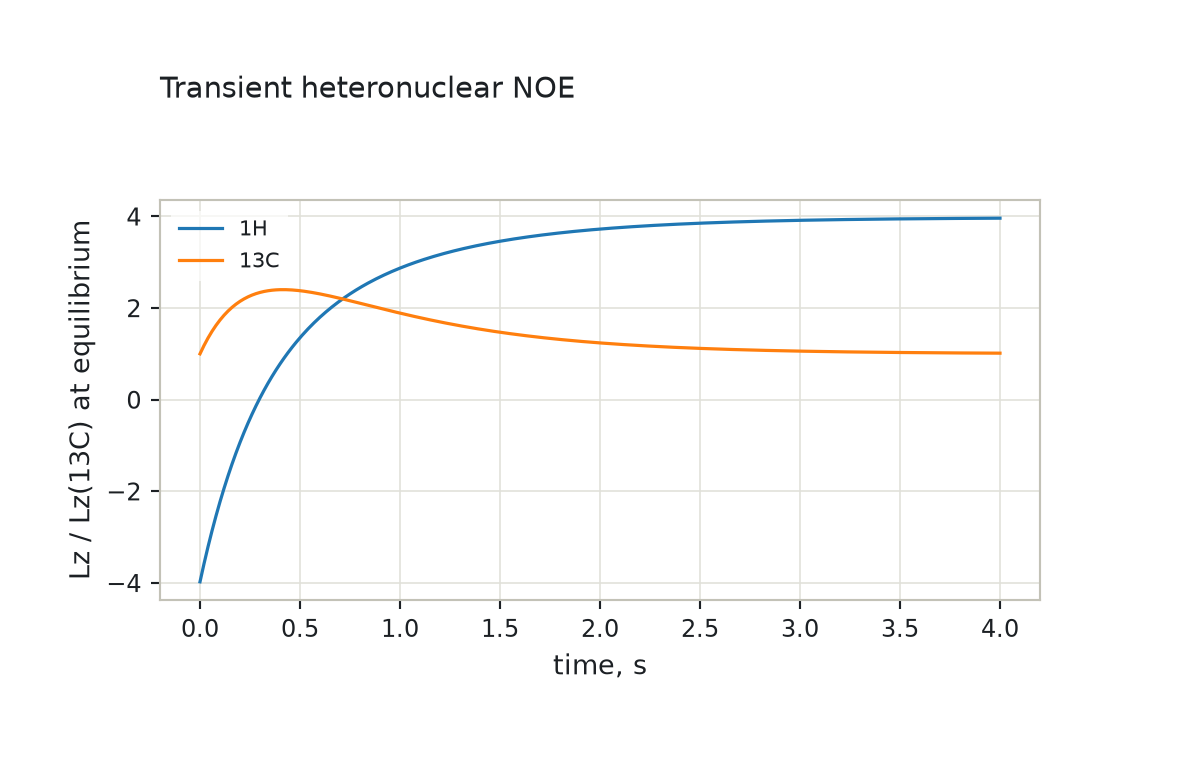

In [10]:
import plotly.graph_objects as go

t = dt * np.arange(nsteps + 1)
scale = np.vdot(Lz2, rho_eq).real
fig = go.Figure()
fig.add_trace(go.Scatter(x=t, y=noe[0] / scale, name="1H"))
fig.add_trace(go.Scatter(x=t, y=noe[1] / scale, name="13C"))
fig.update_layout(title="Transient heteronuclear NOE", xaxis_title="time, s",
                  yaxis_title="Lz / Lz(13C) at equilibrium", width=600, height=380)
fig

The carbon magnetisation rises above its equilibrium value before
returning to it: the heteronuclear Overhauser effect. The curves follow
the two-spin Solomon equations, which `tests/unit/test_relaxation.py`
checks against a matrix exponential.

## Relaxation in the contexts

`liquid`, `crystal` and `powder` build `R` with `relaxation(spin_system)` (at each
grid orientation in `powder`, so anisotropic rate tensors and the thermal
equilibrium of anisotropic systems follow the orientation) and hand it to
the pulse sequence together with `H` and `K`. A system without
`inter["relaxation"]` gets `R = 0`, as in Spinach.

## What is not ported yet

- the Lindblad, Nottingham and Weizmann DNP theories, the Nakajima-Zwanzig
  evaluation of the Redfield kernel, and orientation functions for rates;
- relaxation in Hilbert space other than `damp`;
- bosonic mode dissipators.

## Checking results against Spinach

`tests/unit/test_relaxation.py` checks Redfield rates against the Solomon
equations, the T1/T2 and damping models against their definitions, the
equilibrium state against the Boltzmann distribution, both thermalisation
methods, the transient NOE against the two-spin Solomon solution, SRSK
against Abragam's expressions and SRFK against the explicit integral.
`tests/slice/test_scalar_parity.py` compares the SRFK and SRSK
superoperators, equilibrium states and NOE trajectories of three systems
with Spinach 2.13 fixtures (FR-008).
`tests/slice/test_relax_parity.py` compares `R` (isotropic and at an
orientation), equilibrium states, both thermalised superoperators and
NOE trajectories of five systems (heteronuclear and homonuclear NOE
pairs, a three-spin system with CSA, dipolar couplings and secular
retention under IME, axial diffusion with dynamic frequency shifts, and
the T1/T2 model plus anisotropic damping) with Spinach 2.13
fixtures (FR-005 in `porting/FIXTURE_REQUESTS.md`); those tests skip
while the fixtures are absent. Measured agreement over the five cases
(largest elementwise difference relative to the largest element):

| stage | difference from Spinach |
|---|---|
| relaxation superoperators, isotropic and at an orientation | 0 (identical after the `rlx_zero` rounding) |
| equilibrium states | 3e-25 |
| thermalised superoperators (IME, DiBari-Levitt) | 1e-15 |
| NOE trajectories (`multichannel`, up to 1000 steps) | 5e-15 |